<a href="https://colab.research.google.com/github/ANJALICHAMOLI/Deep-Learning/blob/main/cats_dogs_hyperparmeter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salader/dogsvscats")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dogsvscats' dataset.
Path to dataset files: /kaggle/input/dogsvscats


In [ ]:
import matplotlib.pyplot as plt


In [ ]:
import os
print(os.listdir(path)[:5])

['test', 'train', 'catsvsdogs']


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPool2D,Flatten,BatchNormalization,Dropout
from tensorflow.keras import layers

ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
train_data = keras.utils.image_dataset_from_directory(
    directory=path + "/train",
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(128,128),
    validation_split=0.2,
    subset='training',
    seed=42
)

val_data = keras.utils.image_dataset_from_directory(
    directory=path + "/test",
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(128,128),
    validation_split=0.2,
    subset='validation',
    seed=42
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [ ]:
#since every value is btw 0-255 so we normalise it first
def norm(image,label):
  image=tf.cast(image/255,tf.float32)
  return image,label

train_data=train_data.map(norm)
val_data=val_data.map(norm)

In [ ]:
#CNN model

model=Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding ='valid',activation='relu',input_shape=(256,256,3)))
model.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding ='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding ='valid',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())


model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history=model.fit(train_data,epochs=10,validation_data=val_data)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 99s 143ms/step - accuracy: 0.6638 - loss: 0.6151 - val_accuracy: 0.7470 - val_loss: 0.5137
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.7682 - loss: 0.4810 - val_accuracy: 0.7908 - val_loss: 0.4462
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.8297 - loss: 0.3764 - val_accuracy: 0.7884 - val_loss: 0.4546
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.8922 - loss: 0.2548 - val_accuracy: 0.7916 - val_loss: 0.5592
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 89ms/step - accuracy: 0.9390 - loss: 0.1538 - val_accuracy: 0.7632 - val_loss: 0.7949
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 83s 91ms/step - accuracy: 0.9617 - loss: 0.1031 - val_accuracy: 0.7890 - val_loss: 1.0265
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.9732 - loss: 0.0717 - val_accuracy: 0.7902 - val_loss: 1.1055
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 85ms/step - accuracy: 0.9837 - loss: 0.0490 -

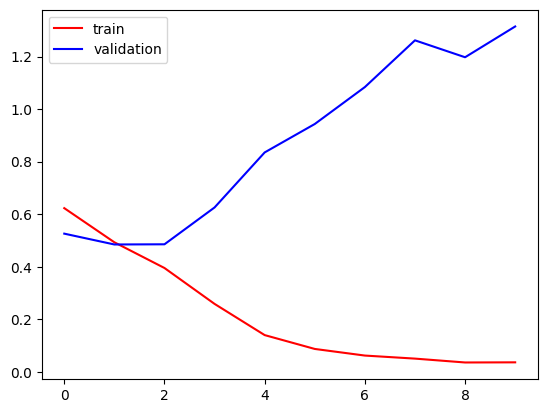

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
#the above shows clear case of overfitting ads trating eroro is less than val hence not performing well on tetsing data

In [ ]:
#applying techniques to reduce over fitting

#l1/l2
#dropout
#batch norm
#reduce complexity

In [ ]:
#CNN model

model1=Sequential()

model1.add(Conv2D(32,kernel_size=(3,3),padding ='valid',activation='relu',input_shape=(256,256,3)))
model1.add(BatchNormalization())#stablized output
model1.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Conv2D(64,kernel_size=(3,3),padding ='valid',activation='relu'))
model1.add(BatchNormalization())
model1.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Conv2D(128,kernel_size=(3,3),padding ='valid',activation='relu'))
model1.add(BatchNormalization())
model1.add(MaxPool2D(pool_size=(2,2),strides=2,padding='valid'))

model1.add(Flatten())


model1.add(Dense(128,activation='relu'))
model1.add(Dropout(0.1)) #reducing nurons
model1.add(Dense(64,activation='relu'))
model1.add(Dropout(0.1))
model1.add(Dense(1,activation='sigmoid'))

In [ ]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model1.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history1=model1.fit(train_data,epochs=10,validation_data=val_data)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 91ms/step - accuracy: 0.5955 - loss: 1.1713 - val_accuracy: 0.6514 - val_loss: 0.6370
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.6956 - loss: 0.5955 - val_accuracy: 0.7168 - val_loss: 0.5543
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 92ms/step - accuracy: 0.7583 - loss: 0.5005 - val_accuracy: 0.6800 - val_loss: 0.5843
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 89ms/step - accuracy: 0.8018 - loss: 0.4376 - val_accuracy: 0.7052 - val_loss: 0.5946
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 87s 97ms/step - accuracy: 0.8326 - loss: 0.3845 - val_accuracy: 0.7788 - val_loss: 0.5079
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.8732 - loss: 0.2981 - val_accuracy: 0.8142 - val_loss: 0.5050
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 95ms/step - accuracy: 0.9076 - loss: 0.2294 - val_accuracy: 0.7608 - val_loss: 0.6866
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.9320 - loss: 0.1687 - 

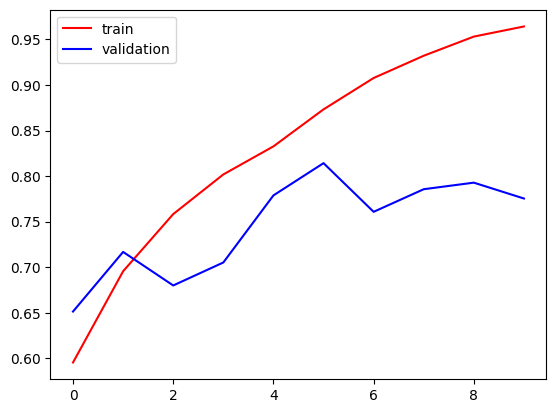

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

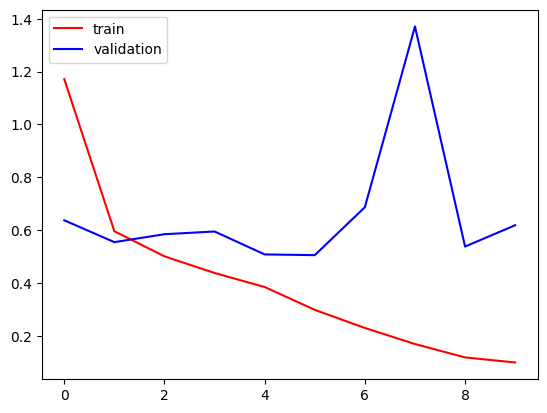

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

In [ ]:
import cv2

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cat_img.jpg to cat_img.jpg


In [ ]:
test_img= cv2.imread('cat_img.jpg')

(-0.5, 3131.5, 3131.5, -0.5)

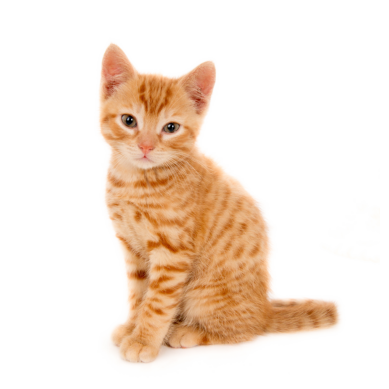

In [ ]:
img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.axis('off')

In [ ]:
img.shape

(3132, 3132, 3)

In [ ]:
img = cv2.resize(img,(256,256))

In [ ]:
img.shape

(256, 256, 3)

In [ ]:
img= img.reshape((1,256,256,3))

In [ ]:
pred=model.predict(img)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 582ms/step


In [ ]:
print(pred)

[[0.]]


In [ ]:
!pip install optuna

In [ ]:
import optuna


In [ ]:
def objective(trial):

    model = keras.Sequential([
        keras.Input(shape=(256,256,3)),

        layers.Conv2D(trial.suggest_categorical("filters", [32,64,128]),
                      (trial.suggest_categorical("kernel", [3,5]),
                       trial.suggest_categorical("kernel", [3,5])),
                      activation='relu'),

        layers.MaxPooling2D((2,2)),

        layers.Conv2D(trial.suggest_categorical("filters", [32,64,128]) * 3,
                      (3,3),
                      activation='relu'),

        layers.MaxPooling2D((2,2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(trial.suggest_categorical("dense_units", [64,128,256]), activation='relu'),

        layers.Dropout(trial.suggest_float("dropout", 0.2, 0.5)),

        layers.Dense(1, activation='sigmoid')
    ])

    lr = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=5,
        batch_size=32,
        verbose=0
    )

    return max(history.history['val_accuracy'])

In [ ]:
study = optuna.create_study(direction='maximize',sampler= optuna.samplers.TPESampler())#max val acc

study.optimize(objective, n_trials=10) #10 trails find best hyper parameter

[I 2026-05-12 18:10:38,036] A new study created in memory with name: no-name-248c7043-f9e4-46e1-8d85-de66b5ce95da
[I 2026-05-12 18:20:07,865] Trial 0 finished with value: 0.676800012588501 and parameters: {'filters': 64, 'kernel': 3, 'dense_units': 128, 'dropout': 0.3482225548200843, 'learning_rate': 0.002168036413367229}. Best is trial 0 with value: 0.676800012588501.
[I 2026-05-12 18:37:33,690] Trial 1 finished with value: 0.5669999718666077 and parameters: {'filters': 128, 'kernel': 5, 'dense_units': 64, 'dropout': 0.2883741093820196, 'learning_rate': 0.0036182076756305}. Best is trial 0 with value: 0.676800012588501.
[I 2026-05-12 18:42:02,718] Trial 2 finished with value: 0.6481999754905701 and parameters: {'filters': 32, 'kernel': 5, 'dense_units': 128, 'dropout': 0.21119618810015253, 'learning_rate': 0.0003481459689797507}. Best is trial 0 with value: 0.676800012588501.
[I 2026-05-12 18:46:43,159] Trial 3 finished with value: 0.628000020980835 and parameters: {'filters': 32, 'ke

In [ ]:
IMG_SIZE=256

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.optimizers import Adam

model = Sequential()

# ----- Conv Block 1 -----
model.add(
    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation='relu',
        padding='same',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

# ----- Conv Block 2 -----
model.add(
    Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2)))

# ----- Conv Block 3 -----
model.add(
    Conv2D(
        filters=256,
        kernel_size=(3,3),
        activation='relu',
        padding='same'
    )
)

model.add(MaxPooling2D(pool_size=(2,2)))

# ----- Better Alternative to Flatten -----
model.add(GlobalAveragePooling2D())

# ----- Dense Part -----
model.add(Dense(64, activation='relu'))

model.add(Dropout(0.23))

# Binary classification
model.add(Dense(1, activation='sigmoid'))

# ----- Compile -----
optimizer = Adam(learning_rate=0.0017)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

KeyboardInterrupt: 

In [ ]:
history=model.fit(train_data,epochs=10,validation_data=val_data)

Epoch 1/10
 13/625 ━━━━━━━━━━━━━━━━━━━━ 3:24:42 20s/step - accuracy: 0.5045 - loss: 45.7309

In [ ]:
from google.colab import files
files.upload()

In [ ]:
!pip install tensorflow==2.16.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 811.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 590.8/590.8 MB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 51.7 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.20.0
    Uninstalling tensorboard-2.20.0:
      Success

In [ ]:
!pip install -q ml_dtypes==0.5.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 13.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires ml-dtypes~=0.3.1, but you have ml-dtypes 0.5.0 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.16.2 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.16.2 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.16.2 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.


In [ ]:
from tensorflow import keras

model = keras.models.load_model("dogs_vs_cats_model.keras")

In [ ]:
loss, accuracy = model.evaluate(val_data)
print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Loss: {loss:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 484s 3s/step - accuracy: 0.7362 - loss: 0.5567
Validation Accuracy: 73.62%
Validation Loss: 0.5567
